Project Title : A Balochi Romanisation and Cross-Script Transliteration system using ByT5-Small

Noorkhatoon(021)Gulnisa(033)Sadia(003)

In [ ]:
!pip install -q pandas openpyxl scikit-learn matplotlib transformers datasets accelerate jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 64.7 MB/s eta 0:00:00


Load the Balochi Sentence Datasets

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

print("first files:")
for filename in uploaded.keys():
    print(filename)

Saving part 1 project.xlsx to part 1 project.xlsx
first files:
part 1 project.xlsx


Load the Balochi Words Datasets

In [ ]:
from google.colab import files

uploaded_second = files.upload()

print("Second dataset uploaded:")
for filename in uploaded_second.keys():
    print(filename)

Saving words Dataset.xlsx to words Dataset.xlsx
Second dataset uploaded:
words Dataset.xlsx


Explore and Inspect the Datasets

In [ ]:
import pandas as pd

print("First dataset files:", list(uploaded.keys()))
print("Second dataset files:", list(uploaded_second.keys()))

sentence_file = next(iter(uploaded.keys()))
word_file = next(iter(uploaded_second.keys()))

sentence_df = pd.read_excel(sentence_file)
word_df = pd.read_excel(word_file)

print("\n===== SENTENCE DATASET =====")
print("Total rows:", len(sentence_df))
print("Columns:", sentence_df.columns.tolist())
display(sentence_df.head())

print("\n===== WORD DATASET =====")
print("Total rows:", len(word_df))
print("Columns:", word_df.columns.tolist())
display(word_df.head())



First dataset files: ['part 1 project.xlsx']
Second dataset files: ['words Dataset.xlsx']

===== SENTENCE DATASET =====
Total rows: 2000
Columns: ['ID', 'Arabic', 'Latin']


,ID,Arabic,Latin
0,1,آئی ءَ سفر ءَ وتی کیمرہ زُرتگ ات گوں۔,Aٓaiiá sapará wati kimrh zortag et gón.
1,2,بالی گُراب ءَ چہ جمبراں بُرزتر بال کت۔,Báli gorábá che jmbrán borztr bál kot.
2,3,تیر امبار ءِ چھتءَ کمک کنت۔,Tyar ambáray chhtá komk kant.
3,4,آئی ءَ ہرزبند ءَ تازہ ئیں گریپ فروٹے وارت۔,Aٓaiiá harazbandá tázh aién grip próthé wárt.
4,5,بازیں ائرلائنانی پہ گنداوگ ءَ تچکیں بالی گُراب...,Bázén aairláaináni pa gandáwagá tachkén báli g...



===== WORD DATASET =====
Total rows: 988
Columns: ['Arabic', 'Latin']


,Arabic,Latin
0,ٹاب,tháb
1,ٹاپ,tháp
2,ٹاپار,thápár
3,ٹاپَل,thápal
4,ٹاپو,thápu


Clean and Preprocess the Data

In [ ]:

sentence_data = sentence_df[["Arabic", "Latin"]].copy()
word_data = word_df[["Arabic", "Latin"]].copy()

print("SENTENCE DATASET")
print("Missing values:")
print(sentence_data.isnull().sum())
print("Duplicate rows:", sentence_data.duplicated().sum())

print("\nWORD DATASET")
print("Missing values:")
print(word_data.isnull().sum())
print("Duplicate rows:", word_data.duplicated().sum())

print("\nSentence length statistics:")
print(sentence_data["Arabic"].dropna().astype(str).str.len().describe())

print("\nWord length statistics:")
print(word_data["Arabic"].dropna().astype(str).str.len().describe())

SENTENCE DATASET
Missing values:
Arabic    0
Latin     0
dtype: int64
Duplicate rows: 5

WORD DATASET
Missing values:
Arabic    0
Latin     0
dtype: int64
Duplicate rows: 1

Sentence length statistics:
count    2000.000000
mean       36.058000
std        10.286279
min         9.000000
25%        29.000000
50%        35.000000
75%        43.000000
max        81.000000
Name: Arabic, dtype: float64

Word length statistics:
count    988.000000
mean       6.766194
std        2.203201
min        2.000000
25%        5.000000
50%        6.000000
75%        8.000000
max       17.000000
Name: Arabic, dtype: float64


Remove Duplicate Records

In [ ]:
for dataset in [sentence_data, word_data]:
    for column in ["Arabic", "Latin"]:
        dataset[column] = dataset[column].apply(
            lambda x: " ".join(str(x).split())
            if pd.notna(x) else x
        )

sentence_data = sentence_data.drop_duplicates(
    subset=["Arabic", "Latin"]
).reset_index(drop=True)

word_data = word_data.drop_duplicates(
    subset=["Arabic", "Latin"]
).reset_index(drop=True)

print("Cleaning completed!")

print("\nSentence dataset rows:", len(sentence_data))
print("Sentence duplicates:", sentence_data.duplicated().sum())

print("\nWord dataset rows:", len(word_data))
print("Word duplicates:", word_data.duplicated().sum())

print("\nSentence examples:")
display(sentence_data.head())

print("\nWord examples:")
display(word_data.head())

Cleaning completed!

Sentence dataset rows: 1995
Sentence duplicates: 0

Word dataset rows: 987
Word duplicates: 0

Sentence examples:


,Arabic,Latin
0,آئی ءَ سفر ءَ وتی کیمرہ زُرتگ ات گوں۔,Aٓaiiá sapará wati kimrh zortag et gón.
1,بالی گُراب ءَ چہ جمبراں بُرزتر بال کت۔,Báli gorábá che jmbrán borztr bál kot.
2,تیر امبار ءِ چھتءَ کمک کنت۔,Tyar ambáray chhtá komk kant.
3,آئی ءَ ہرزبند ءَ تازہ ئیں گریپ فروٹے وارت۔,Aٓaiiá harazbandá tázh aién grip próthé wárt.
4,بازیں ائرلائنانی پہ گنداوگ ءَ تچکیں بالی گُراب...,Bázén aairláaináni pa gandáwagá tachkén báli g...



Word examples:


,Arabic,Latin
0,ٹاب,tháb
1,ٹاپ,tháp
2,ٹاپار,thápár
3,ٹاپَل,thápal
4,ٹاپو,thápu


Visualization

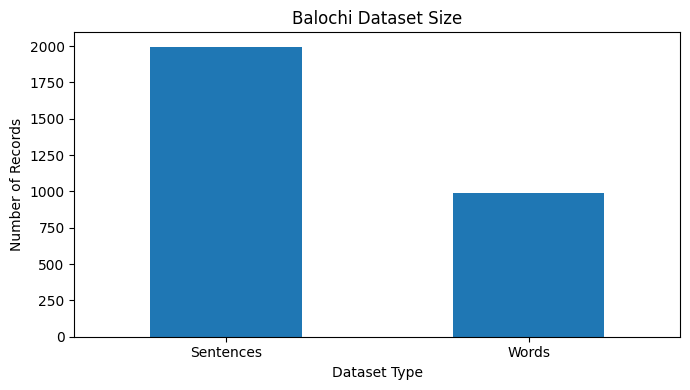

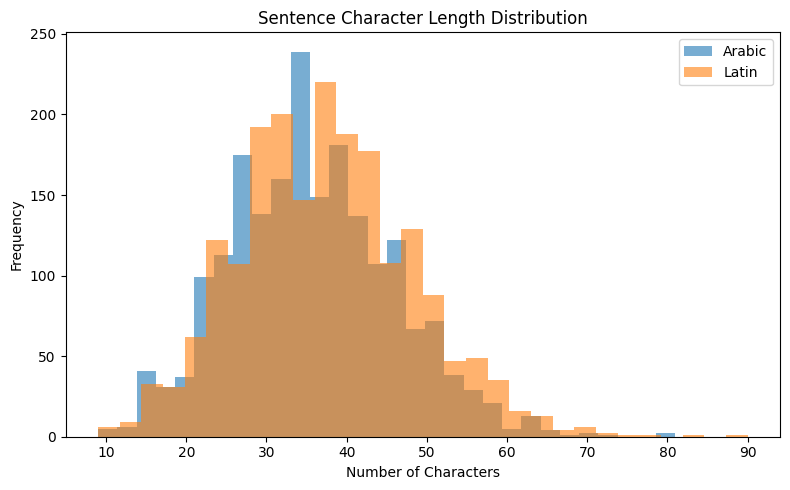

Sentence records: 1995
Word records: 987

Average character lengths:
Arabic: 35.592481203007516
Latin: 37.3984962406015


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Dataset size
sizes = pd.Series({
    "Sentences": len(sentence_data),
    "Words": len(word_data)
})

plt.figure(figsize=(7, 4))
sizes.plot(kind="bar")
plt.title("Balochi Dataset Size")
plt.xlabel("Dataset Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Arabic and Latin character lengths
plt.figure(figsize=(8, 5))
plt.hist(
    sentence_data["Arabic"].dropna().astype(str).str.len(),
    bins=30, alpha=0.6, label="Arabic"
)
plt.hist(
    sentence_data["Latin"].dropna().astype(str).str.len(),
    bins=30, alpha=0.6, label="Latin"
)
plt.title("Sentence Character Length Distribution")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

print("Sentence records:", len(sentence_data))
print("Word records:", len(word_data))
print("\nAverage character lengths:")
print("Arabic:", sentence_data["Arabic"].dropna().astype(str).str.len().mean())
print("Latin:", sentence_data["Latin"].dropna().astype(str).str.len().mean())

Split the Dataset into Training, Validation, and Testing Sets

In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42

def split_dataset(data, dataset_name):

    train_df, temp_df = train_test_split(
        data,
        test_size=0.20,
        random_state=SEED,
        shuffle=True
    )

    val_df, test_df = train_test_split(
        temp_df,
        test_size=0.50,
        random_state=SEED,
        shuffle=True
    )

    print(f"\n{dataset_name}")
    print("Training rows:", len(train_df))
    print("Validation rows:", len(val_df))
    print("Testing rows:", len(test_df))
    print("Total rows:", len(train_df) + len(val_df) + len(test_df))

    return train_df, val_df, test_df

sentence_train, sentence_val, sentence_test = split_dataset(
    sentence_data, "SENTENCE DATASET"
)

word_train, word_val, word_test = split_dataset(
    word_data, "WORD DATASET"
)



SENTENCE DATASET
Training rows: 1596
Validation rows: 199
Testing rows: 200
Total rows: 1995

WORD DATASET
Training rows: 789
Validation rows: 99
Testing rows: 99
Total rows: 987


Dataset Split Verifiction and Saving

In [ ]:
import os

os.makedirs("/content/balochi_processed", exist_ok=True)

splits = {
    "sentence_train": sentence_train,
    "sentence_val": sentence_val,
    "sentence_test": sentence_test,
    "word_train": word_train,
    "word_val": word_val,
    "word_test": word_test
}

for name, dataset in splits.items():
    assert dataset[["Arabic", "Latin"]].notna().all().all(), (
        f"Missing values found in {name}"
    )

    dataset.to_csv(
        f"/content/balochi_processed/{name}.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(f"{name}: {len(dataset)} rows saved")

print("\nAll six datasets saved successfully!")

sentence_train: 1596 rows saved
sentence_val: 199 rows saved
sentence_test: 200 rows saved
word_train: 789 rows saved
word_val: 99 rows saved
word_test: 99 rows saved

All six datasets saved successfully!


Text Preprocessing and input Target Preparation for Transliteration

In [ ]:
PREFIX = "transliterate Balochi to Roman Balochi: "

def prepare_model_data(dataset):
    prepared = dataset.copy()

    prepared["Arabic"] = prepared["Arabic"].astype(str).str.strip()
    prepared["Latin"] = prepared["Latin"].astype(str).str.strip()

    prepared = prepared[
        (prepared["Arabic"] != "") &
        (prepared["Latin"] != "")
    ].reset_index(drop=True)

    prepared["model_input"] = (
        PREFIX + prepared["Arabic"]
    )
    prepared["model_target"] = prepared["Latin"]

    return prepared


sentence_train = prepare_model_data(sentence_train)
sentence_val = prepare_model_data(sentence_val)
sentence_test = prepare_model_data(sentence_test)

word_train = prepare_model_data(word_train)
word_val = prepare_model_data(word_val)
word_test = prepare_model_data(word_test)

print("Text preprocessing completed!")

print("\nExample input:")
print(sentence_train["model_input"].iloc[0])

print("\nExpected Roman output:")
print(sentence_train["model_target"].iloc[0])

print("\nTraining sentence examples:", len(sentence_train))
print("Training word examples:", len(word_train))

Text preprocessing completed!

Example input:
transliterate Balochi to Roman Balochi: مہربانی کن دروازگ ءَ بل پچ اِنت۔

Expected Roman output:
Mehrabáni ken darwázagá bal pach ent.

Training sentence examples: 1596
Training word examples: 789


Load the Pretrained ByT5-Small Model and Tokenizer

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "google/byt5-small"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME
)

model = model.to(device)

print("Model loaded successfully!")
print("Model name:", MODEL_NAME)
print("Device:", device)

Device: cpu


config.json:   0%|          | 0.00/698 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.59k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.20GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (2 outputs left out)

Loading weights:   0%|          | 0/172 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Model loaded successfully!
Model name: google/byt5-small
Device: cpu


Tokenize the Sentence Dataset

In [ ]:
from datasets import Dataset

MAX_SOURCE_LENGTH = 256
MAX_TARGET_LENGTH = 256

def tokenize_batch(batch):
    inputs = tokenizer(
        batch["model_input"],
        max_length=MAX_SOURCE_LENGTH,
        truncation=True
    )

    targets = tokenizer(
        text_target=batch["model_target"],
        max_length=MAX_TARGET_LENGTH,
        truncation=True
    )

    inputs["labels"] = targets["input_ids"]
    return inputs

sentence_train_ds = Dataset.from_pandas(
    sentence_train[["model_input", "model_target"]],
    preserve_index=False
)

sentence_val_ds = Dataset.from_pandas(
    sentence_val[["model_input", "model_target"]],
    preserve_index=False
)

sentence_train_tokenized = sentence_train_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=sentence_train_ds.column_names
)

sentence_val_tokenized = sentence_val_ds.map(
    tokenize_batch,
    batched=True,
    remove_columns=sentence_val_ds.column_names
)

print("Sentence training rows:", len(sentence_train_tokenized))
print("Sentence validation rows:", len(sentence_val_tokenized))
print("Tokenization completed successfully!")

Map:   0%|          | 0/1596 [00:00<?, ? examples/s]

Map:   0%|          | 0/199 [00:00<?, ? examples/s]

Sentence training rows: 1596
Sentence validation rows: 199
Tokenization completed successfully!


Configure Model Training Parameters

In [ ]:
from transformers import Seq2SeqTrainingArguments

training_args = Seq2SeqTrainingArguments(
    output_dir="/content/balochi_sentence_model",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-4,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=5,
    weight_decay=0.01,
    predict_with_generate=True,
    generation_max_length=256,
    fp16=False,
    report_to="none",
    save_total_limit=2,
    load_best_model_at_end=True
)

print("Training settings ready!")
print("Epochs:", training_args.num_train_epochs)
print("Batch size:", training_args.per_device_train_batch_size)
print("Learning rate:", training_args.learning_rate)

Training settings ready!
Epochs: 5
Batch size: 4
Learning rate: 0.0002


 the Sequence-to-Sequence Trainer Initialization for ByT5 Fine-Tuning

In [ ]:
from transformers import DataCollatorForSeq2Seq, Seq2SeqTrainer

data_collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model
)

trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=sentence_train_tokenized,
    eval_dataset=sentence_val_tokenized,
    data_collator=data_collator,
    processing_class=tokenizer
)

print("Sentence trainer ready!")

Sentence trainer ready!


Fine-Tuning the Pretrained ByT5-Small Model for Balochi Romanisation

In [ ]:
training_result = trainer.train()

print("Sentence model training completed!")
print("Training loss:", training_result.training_loss)

Epoch,Training Loss,Validation Loss
1,No log,0.129049
2,0.602145,0.085060
3,0.126408,0.070934
4,0.078588,0.064953
5,0.078588,0.064445


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Sentence model training completed!
Training loss: 0.21667762794590234


Save the Trained  Model

In [ ]:
import os

SAVE_PATH = "/content/balochi_sentence_model/final_model"

os.makedirs(SAVE_PATH, exist_ok=True)

model.save_pretrained(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("Sentence model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Sentence model saved successfully!


Test the Model on Held-Out Test Data

In [ ]:
import torch

def romanise_balochi(text):
    model.eval()

    input_text = "transliterate Balochi to Roman Balochi: " + text

    inputs = tokenizer(
        input_text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(next(model.parameters()).device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=128,
            num_beams=4
        )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

test_sentence = "من رواگا یا"

prediction = romanise_balochi(test_sentence)

print("Original Balochi:", test_sentence)
print("Predicted Roman Balochi:", prediction)

Original Balochi: من رواگا یا
Predicted Roman Balochi: Man rwágá yá


Evaluating Model Prediction on the Held-out Test Daraset

In [ ]:
for i in range(min(5, len(sentence_test))):
    original = sentence_test.iloc[i]["Arabic"]
    expected = sentence_test.iloc[i]["Latin"]

    predicted = romanise_balochi(original)

    print("Original:", original)
    print("Correct Roman:", expected)
    print("Model Prediction:", predicted)
    print("-" * 50)

Original: آ کلاکے پیسر جوزگ ءُ مارشتانی سر ءُ چیر بوئگ ءَ اجّکہ ات۔
Correct Roman: Aٓ kláké pésar józag o márshtáni ser o chér bóaigá ajekkah et.
Model Prediction: Aٓ kláké pésar józag o márshtáni ser o chér bóaigá ejjkh et.
--------------------------------------------------
Original: آ دراجیں تگے ءَ گوں بال ءَ چگل دنت۔
Correct Roman: Aٓ drájén togéá gón bálá chagal dant.
Model Prediction: Aٓ drájén tgéá gón bálá chagal dant.
--------------------------------------------------
Original: آ پولیٹیکل سائنس وانیت۔
Correct Roman: Aٓ pólithikl sáens wánit.
Model Prediction: Aٓ pólithikl sáains wánit.
--------------------------------------------------
Original: کہول ءِ مردماں چھٹی ماں ہنہ گوٛرم ءَ پہ وشّی گوٛازینت۔
Correct Roman: Kahólay mardomán chhthi maán hnh góٛrmá pa wasshi góٛázint.
Model Prediction: Kahólay mardomán chhthi maán hanh góٛrmá pa wasshi góٛázint.
--------------------------------------------------
Original: تو من ءَ سک باز دوست ئے ۔
Correct Roman: Taw maná sak báz dóstay.

Calculate Approximate Character Accuracy

In [ ]:
from jiwer import wer, cer

references = []
predictions = []

for i in range(len(sentence_test)):
    original = sentence_test.iloc[i]["Arabic"]
    correct_roman = sentence_test.iloc[i]["Latin"]

    predicted_roman = romanise_balochi(original)

    references.append(str(correct_roman).strip())
    predictions.append(str(predicted_roman).strip())

character_error = cer(references, predictions)
word_error = wer(references, predictions)

print("Character Error Rate (CER):", round(character_error, 4))
print("Word Error Rate (WER):", round(word_error, 4))
print("Character Accuracy (approx.):", round(max(0, 1 - character_error) * 100, 2), "%")

Character Error Rate (CER): 0.0218
Word Error Rate (WER): 0.0901
Character Accuracy (approx.): 97.82 %


Generate Roman Balochi Predictions for User Input

In [ ]:
sentence = input("Enter your Balochi sentence here: ")

prediction = romanise_balochi(sentence)

print("Original Balochi:", sentence)
print("Predicted Roman Balochi:", prediction)


Enter your Balochi sentence here: من اے گپ اش کنگ ءَ گل بوتاں
Original Balochi: من اے گپ اش کنگ ءَ گل بوتاں
Predicted Roman Balochi: Man é gap esh knagá gal bután
